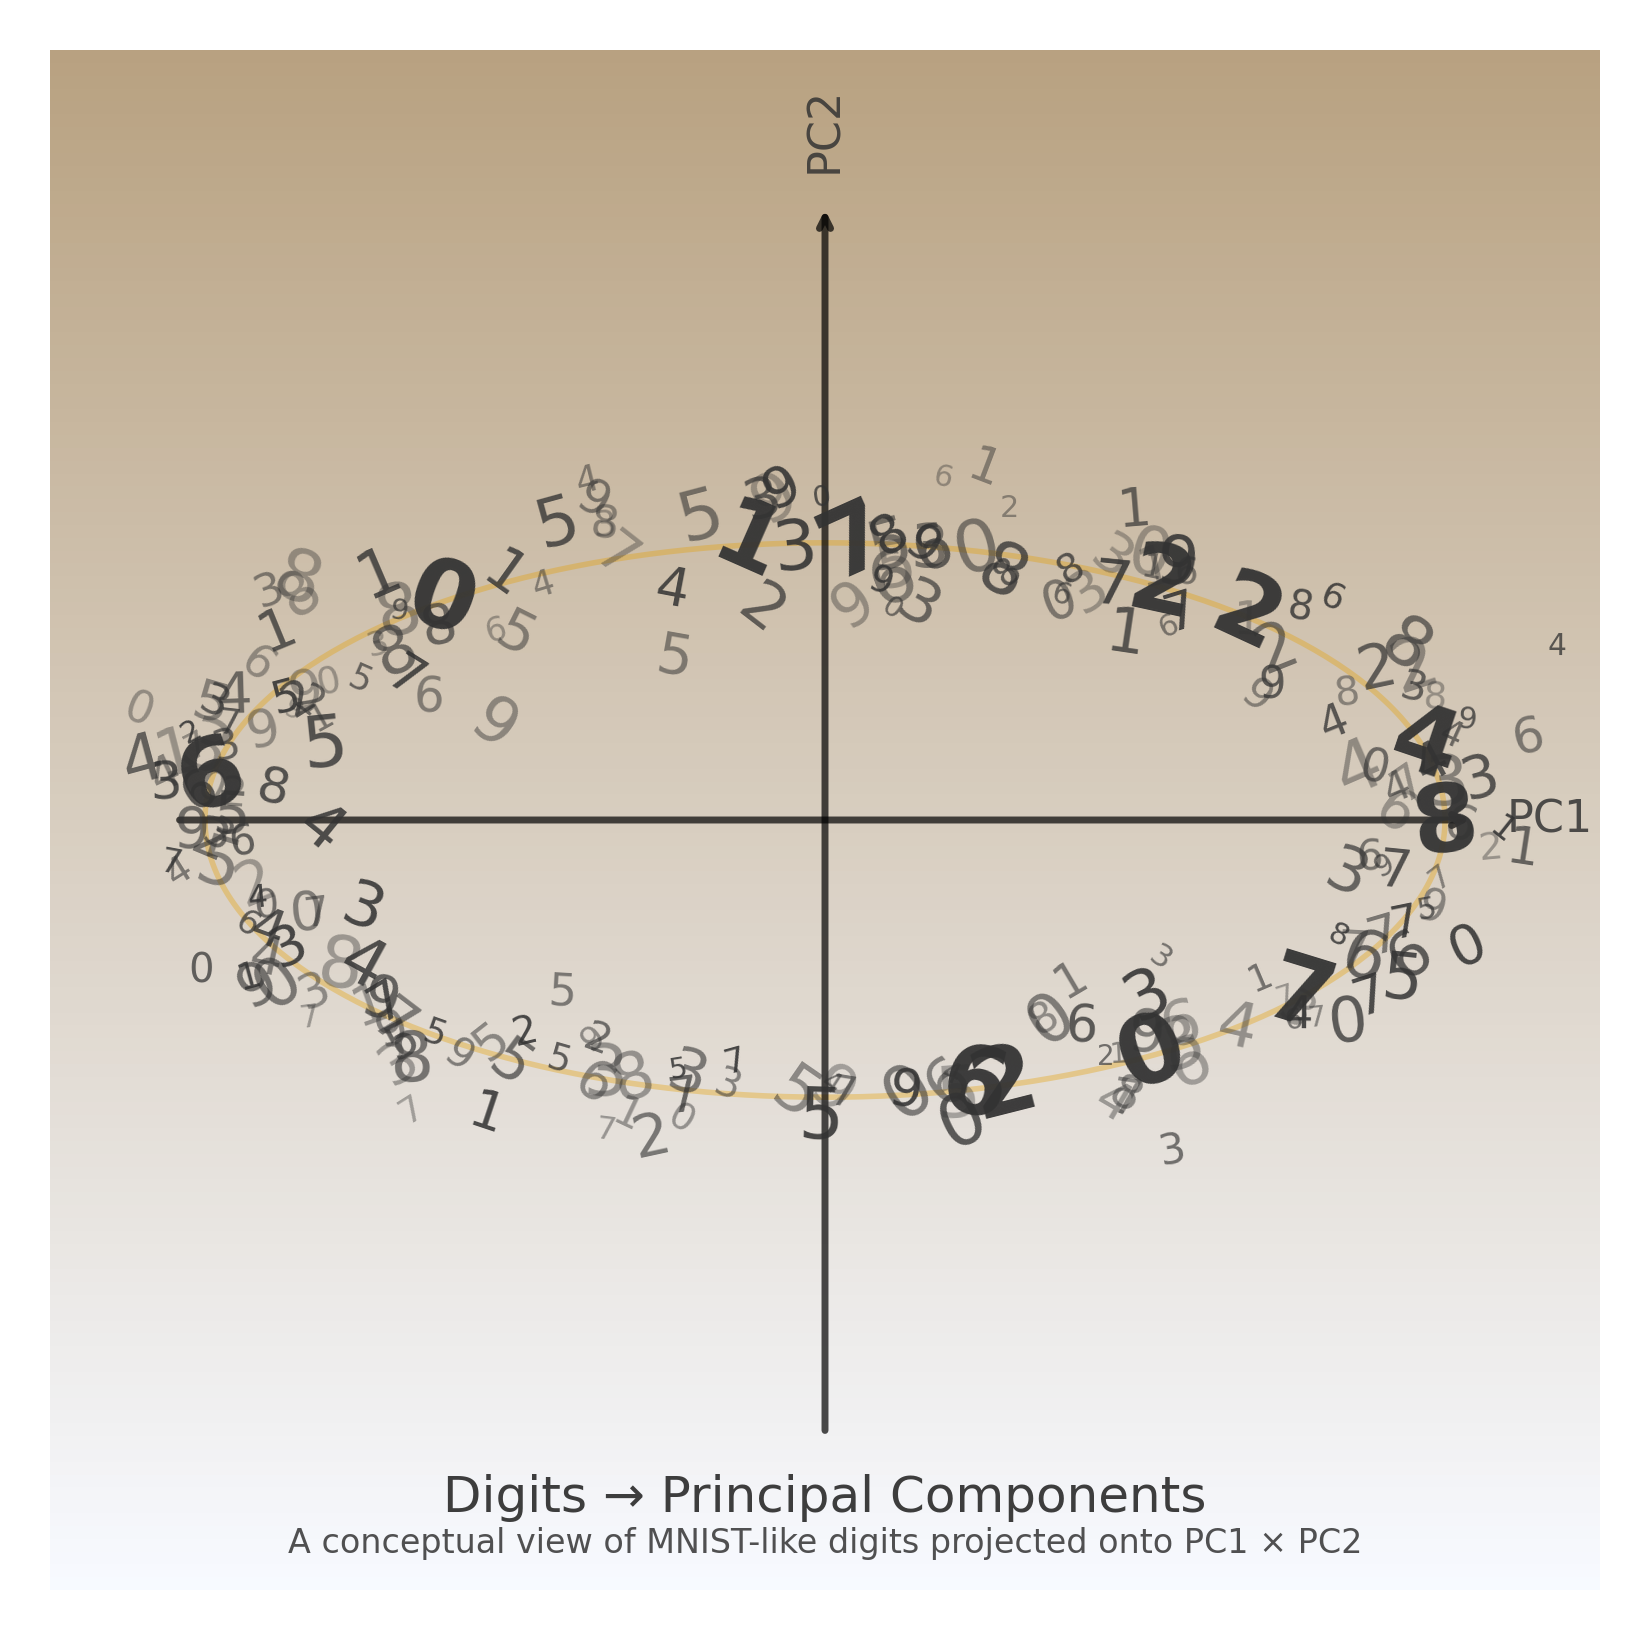

`MNIST` ("Modified National Institute of Standards and Technology") is the de facto “hello world” dataset of computer vision. Since its release in 1999, this classic dataset of handwritten images has served as the basis for benchmarking classification algorithms. As new machine learning techniques emerge, MNIST remains a reliable resource for researchers and learners alike.


`Full name` : Modified National Institute of Standards and Technology dataset.

`Release year` : 1999, by Yann LeCun, Corinna Cortes, and Christopher J.C. Burges.

`Type`: A benchmark dataset for computer vision and machine learning.

`Domain`: Handwritten digit recognition (0–9).

### 📊 Dataset Characteristics

`Images`: 42000 total 

`Classes`: 10 (digits 0 through 9).

`Format`: 28×28 pixel grayscale images (784 features if flattened).

`Pixel range`: 0 (white) → 255 (black).



# <p style="font-family: 'Amiri'; font-size: 3rem; color: #0f172a; text-align: center; margin: 0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.25); background-color: #dbeafe; padding: 20px; border-radius: 20px; border: 8px solid #0f172a; width:95%">📦 Importing Libraries</p>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# <p style="font-family: 'Amiri'; font-size: 3rem; color: #0f172a; text-align: center; margin: 0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.25); background-color: #dbeafe; padding: 20px; border-radius: 20px; border: 8px solid #0f172a; width:95%">📂 Loading Dataset</p>

In [ ]:
df_train = pd.read_csv("/kaggle/input/digit-recognizer/train.csv")
df_train.head()

In [ ]:
df_train.shape

In [ ]:
df_train.sample()

In [ ]:
plt.imshow(df_train.iloc[2655,1:].values.reshape(28,28))

# <p style="font-family: 'Amiri'; font-size: 3rem; color: #0f172a; text-align: center; margin: 0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.25); background-color: #dbeafe; padding: 20px; border-radius: 20px; border: 8px solid #0f172a; width:95%">⚙️ Applying KNN</p>

In [ ]:
X = df_train.drop("label", axis=1) 
y = df_train["label"]

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
knn = KNeighborsClassifier()

In [ ]:
knn.fit(X_train,y_train)

In [ ]:
y_pred = knn.predict(X_test)
accuracy_score(y_test,y_pred)

# <p style="font-family: 'Amiri'; font-size: 3rem; color: #0f172a; text-align: center; margin: 0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.25); background-color: #dbeafe; padding: 20px; border-radius: 20px; border: 8px solid #0f172a; width:95%">⚙️ PCA Implementation</p>

In [ ]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
pca = PCA(n_components=100)

X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [ ]:
X_train_trf.shape

In [ ]:
knn.fit(X_train_trf,y_train)

y_pred_trf = knn.predict(X_test_trf)

accuracy_score(y_test,y_pred_trf)

# <p style="font-family: 'Amiri'; font-size: 3rem; color: #0f172a; text-align: center; margin: 0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.25); background-color: #dbeafe; padding: 20px; border-radius: 20px; border: 8px solid #0f172a; width:95%">Check For all Components</p>

In [ ]:
df_train.shape

In [ ]:
# for i in range(1,785):
#     pca = PCA(n_components=i)

#     X_train_trf = pca.fit_transform(X_train)
#     X_test_trf = pca.transform(X_test)

#     knn.fit(X_train_trf,y_train)

#     y_pred_trf = knn.predict(X_test_trf)
    
#     print(accuracy_score(y_test,y_pred_trf))
    

# <p style="font-family: 'Amiri'; font-size: 3rem; color: #0f172a; text-align: center; margin: 0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.25); background-color: #dbeafe; padding: 20px; border-radius: 20px; border: 8px solid #0f172a; width:95%">🎨 Visualize The Data</p>

In [ ]:
pca = PCA(n_components=2)

X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [ ]:
X_train_trf.shape

In [ ]:
y_train_trf = y_train.astype(str)

fig = px.scatter(x=X_train_trf[:,0],
                 y=X_train_trf[:,1],
                 color=y_train_trf,
                 color_discrete_sequence=px.colors.qualitative.G10
                )

fig.show()

# <p style="font-family: 'Amiri'; font-size: 3rem; color: #0f172a; text-align: center; margin: 0; text-shadow: 2px 2px 4px rgba(0, 0, 0, 0.25); background-color: #dbeafe; padding: 20px; border-radius: 20px; border: 8px solid #0f172a; width:95%">🎨 Visualize In 3D</p>

In [ ]:
pca = PCA(n_components=3)

X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [ ]:
X_train_trf.shape

In [ ]:
y_train_trf = y_train.astype(str)

fig = px.scatter_3d(df_train,x=X_train_trf[:,0],
                 y=X_train_trf[:,1],
                 z=X_train_trf[:,2],
                 color=y_train_trf,
                )
fig.update_layout(
    margin=dict(l=20,r=20,t=20,b=20)
)


fig.show()

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [ ]:
pca = PCA(n_components=None)

X_train_trf = pca.fit_transform(X_train)
X_test_trf = pca.transform(X_test)

In [ ]:
pca.explained_variance_ratio_

In [ ]:
pca.explained_variance_ratio_.shape

In [ ]:
plt.plot(np.cumsum(pca.explained_variance_ratio_))